In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


### Column meaning (interview ke liye yaad rakho)
| Column | Matlab |
|---|---|
| person_age | Customer ki age |
| person_income | Saalana income |
| person_home_ownership | RENT / OWN / MORTGAGE / OTHER |
| person_emp_length | Kitne saal se job mein |
| loan_intent | Loan kyun liya (education, medical, ...) |
| loan_grade | Loan ka grade (A best, G worst) |
| loan_amnt | Loan amount |
| loan_int_rate | Interest rate |
| loan_percent_income | Loan amount ÷ income |
| cb_person_default_on_file | Pehle kabhi default hua? (Y/N) |
| cb_person_cred_hist_length | Credit history kitne saal ki |
| **loan_status** | **Target: 1 = default, 0 = no default** |

## Step 4: Target variable check (class imbalance)
Dekho kitne % customers default hue. Agar default bahut kam hain (jaise ~22%), to data **imbalanced** hai. Isliye sirf accuracy se model judge nahi karte.

loan_status
0    25473
1     7108
Name: count, dtype: int64

loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


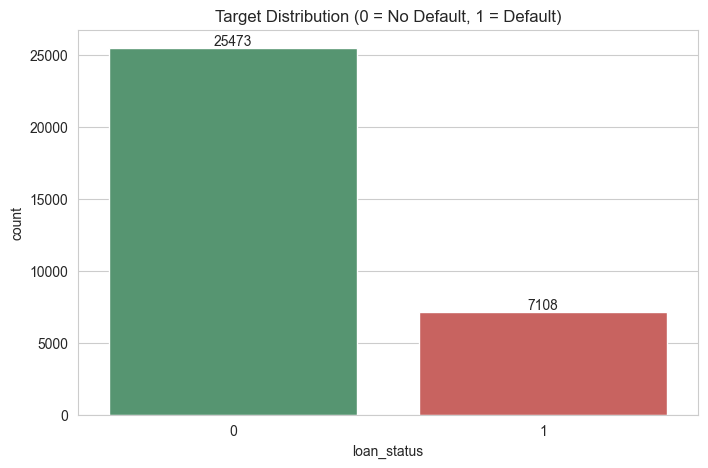

In [5]:
print(df["loan_status"].value_counts())
print()
print((df["loan_status"].value_counts(normalize=True) * 100).round(2))

ax = sns.countplot(x="loan_status", data=df, palette=["#4C9F70", "#D9534F"])
ax.set_title("Target Distribution (0 = No Default, 1 = Default)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

## Step 5: Data quality check
### 5.1 Missing values
Kaunse columns mein data missing hai aur kitna %.

,missing_count,missing_percent
loan_int_rate,3116,9.56
person_emp_length,895,2.75


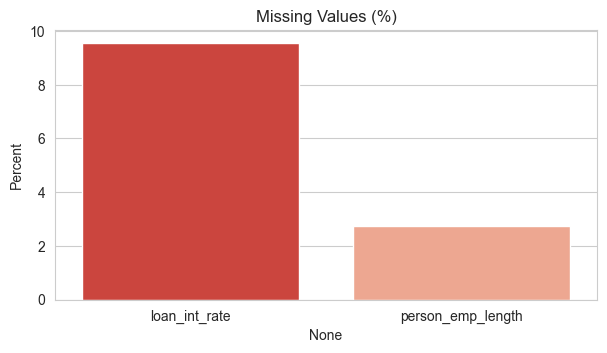

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({"missing_count": missing,
                           "missing_percent": (missing / len(df) * 100).round(2)})
display(missing_df)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=missing_df.index, y=missing_df["missing_percent"], palette="Reds_r")
plt.title("Missing Values (%)")
plt.ylabel("Percent")
plt.show()

### 5.2 Duplicate rows
Duplicate rows model ko bias kar sakte hain, isliye hata dete hain.

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 165


### 5.3 Outliers (galat/unrealistic values)
Boxplot mein dots bahut door dikhein to wo outliers hain. Yahan 3 cheezein check karte hain: age, employment length, income.

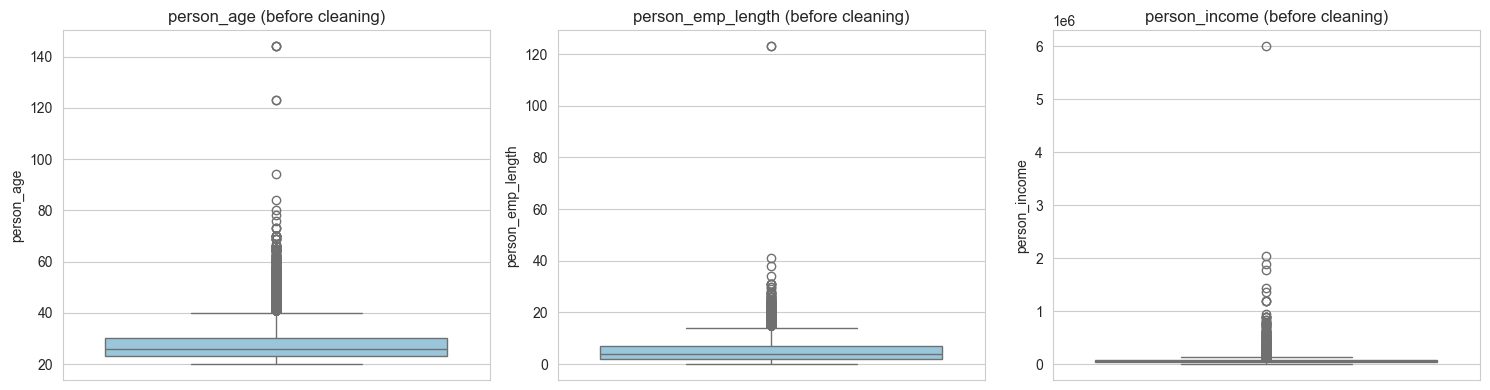

Age > 100          : 5
Emp length > 60 yrs: 2


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["person_age", "person_emp_length", "person_income"]):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(f"{col} (before cleaning)")
plt.tight_layout()
plt.show()

print("Age > 100          :", (df["person_age"] > 100).sum())
print("Emp length > 60 yrs:", (df["person_emp_length"] > 60).sum())

## Step 6: Data Cleaning
Kya karenge:
1. **Duplicates hatao**
2. **Age > 100** hatao — koi 144 saal ka customer realistic nahi hai (data entry error)
3. **Employment length > 60 saal** hatao — age ke hisaab se impossible
4. **Missing values** (`person_emp_length`, `loan_int_rate`) ko hum **abhi fill nahi karenge**. Pipeline ke andar median se fill karenge, taaki test data ki information train mein leak na ho (**data leakage** se bachne ke liye).

In [9]:
rows_before = len(df)

df = df.drop_duplicates()
df = df[df["person_age"] <= 100]
df = df[df["person_emp_length"].isna() | (df["person_emp_length"] <= 60)]
df = df.reset_index(drop=True)

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning : {len(df)}")
print(f"Rows removed        : {rows_before - len(df)}")

Rows before cleaning: 32581
Rows after cleaning : 32409
Rows removed        : 172


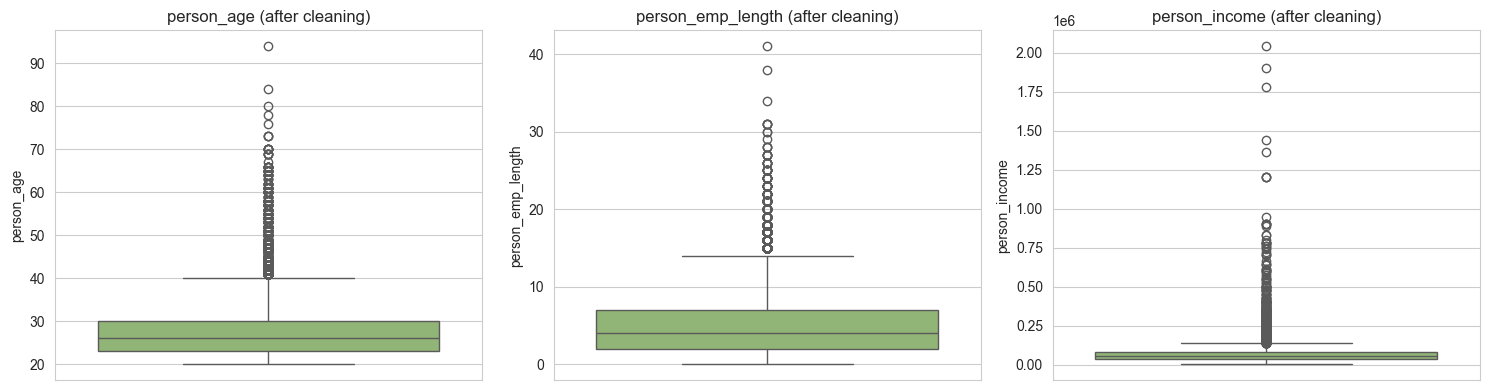

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["person_age", "person_emp_length", "person_income"]):
    sns.boxplot(y=df[col], ax=ax, color="#90be6d")
    ax.set_title(f"{col} (after cleaning)")
plt.tight_layout()
plt.show()

## Step 7: EDA — Univariate Analysis (ek-ek column alag dekhna)
### 7.1 Numerical columns ka distribution
Histogram + KDE curve se pata chalta hai data ka shape kaisa hai (skewed hai ya normal). Income aur loan amount aksar right-skewed hote hain.

Numerical: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


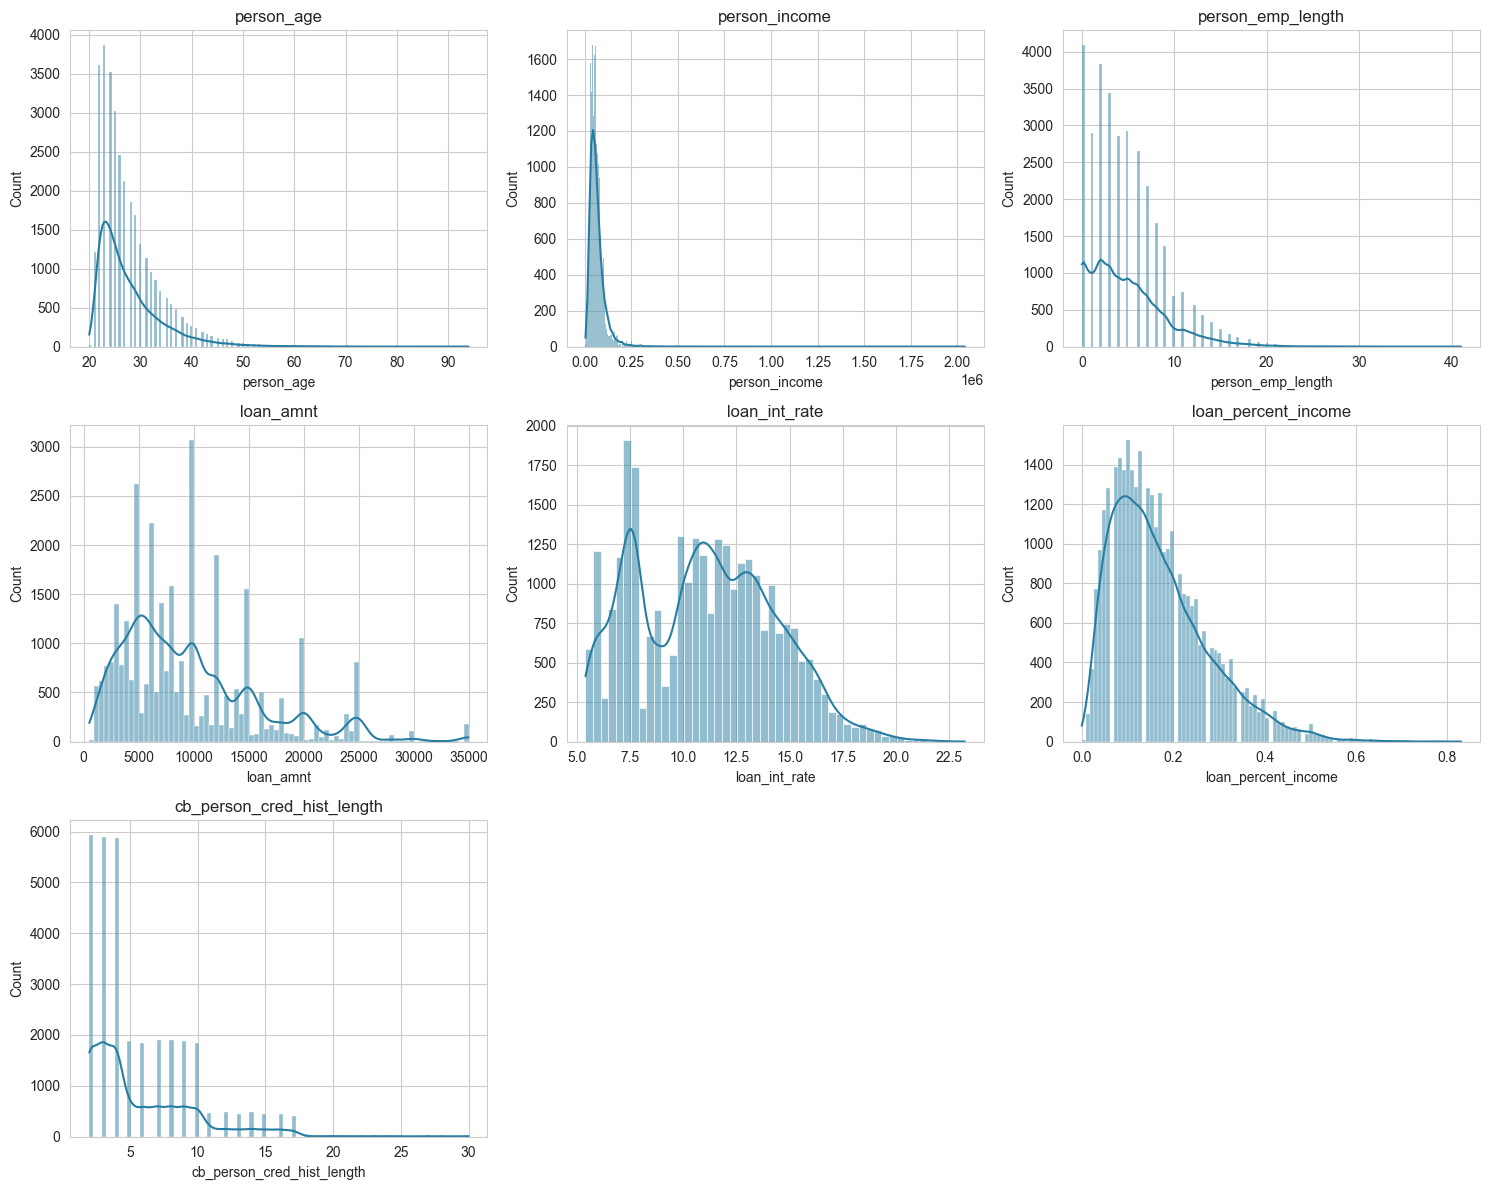

In [11]:
num_cols = df.select_dtypes(include="number").drop(columns="loan_status").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

n = len(num_cols)
rows = int(np.ceil(n / 3))
fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#277da1")
    ax.set_title(col)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 7.2 Categorical columns ka count
Kaunsi category mein kitne customers hain.

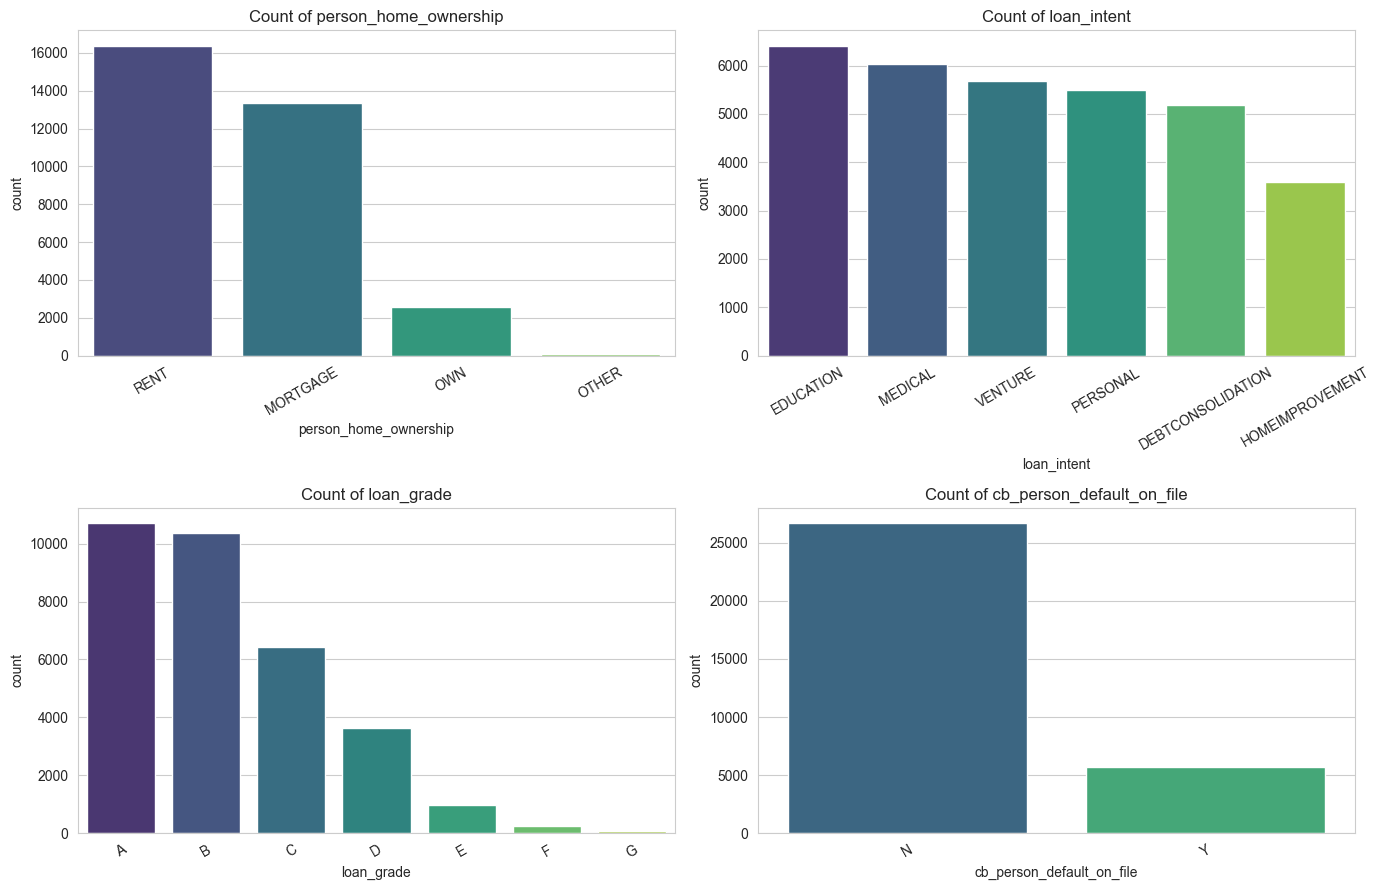

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(x=col, data=df, order=order, ax=ax, palette="viridis")
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## Step 8: EDA — Bivariate Analysis (feature vs default)
### 8.1 Category ke hisaab se Default Rate (%)
Ye sabse important graph hai. Dikhata hai ki kis type ke customers zyada default karte hain.

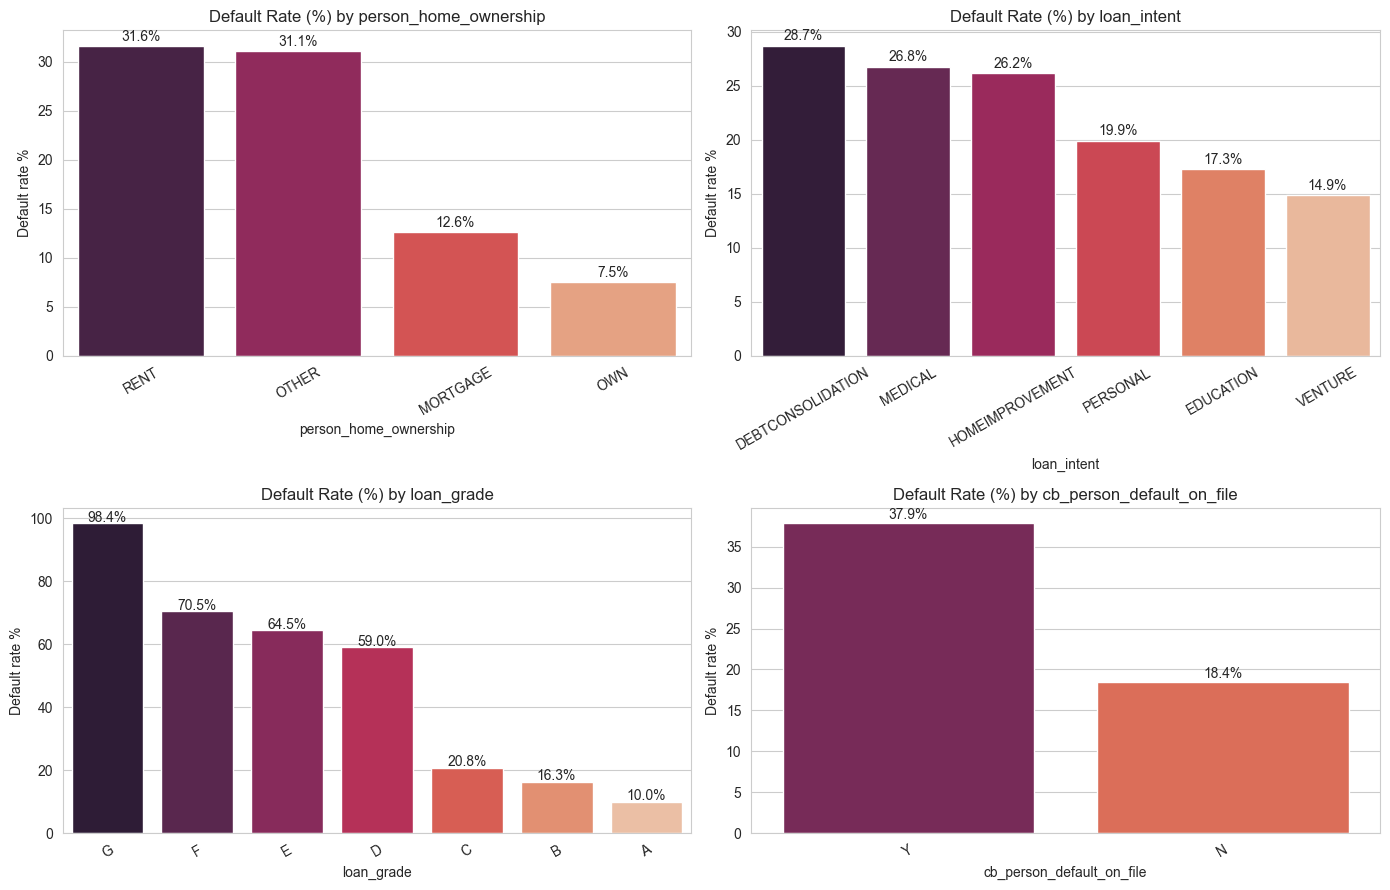

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, cat_cols):
    rate = (df.groupby(col)["loan_status"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="rocket")
    ax.set_title(f"Default Rate (%) by {col}")
    ax.set_ylabel("Default rate %")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

### 8.2 Numerical features vs Default
Boxplot se dekho ki default karne wale (1) aur na karne wale (0) customers mein numbers ka kya fark hai. Jis feature mein fark bada hai, wo model ke liye useful hota hai.

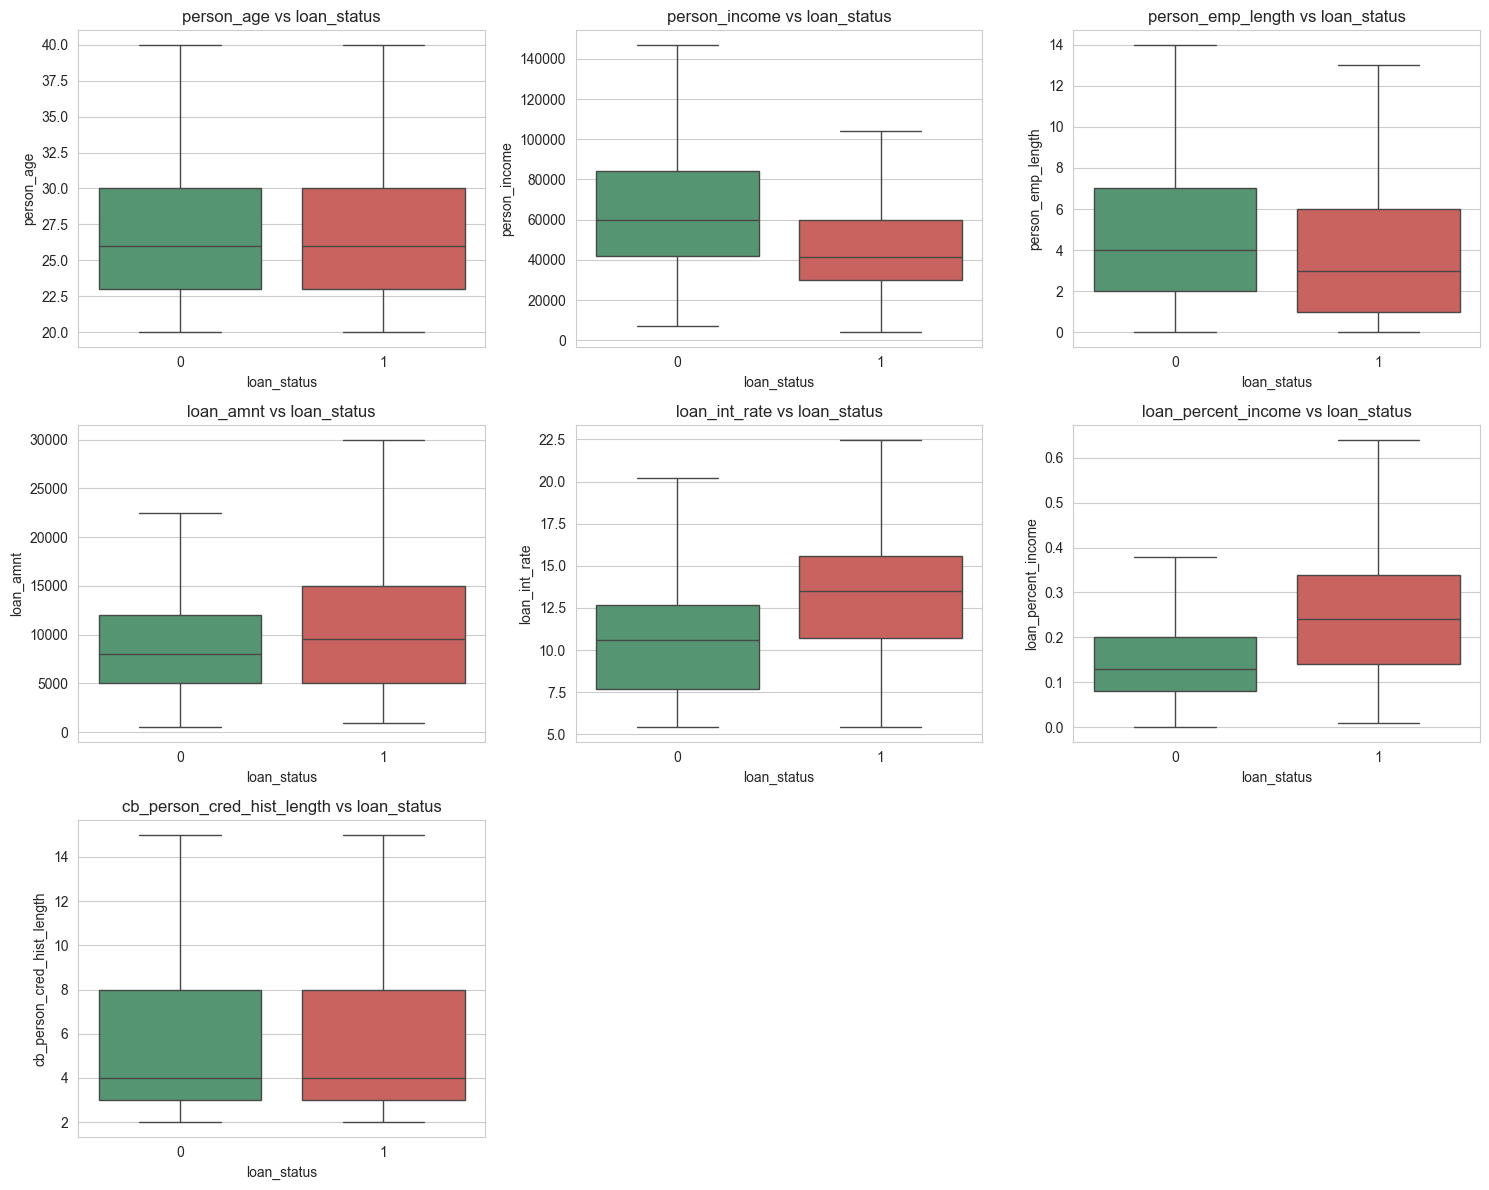

In [14]:
fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x="loan_status", y=col, data=df, ax=ax, showfliers=False, palette=["#4C9F70", "#D9534F"])
    ax.set_title(f"{col} vs loan_status")
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 8.3 Interest rate aur Loan-to-income ka default se relation
Dekho ki interest rate / loan_percent_income badhne par default kaise badhta hai.

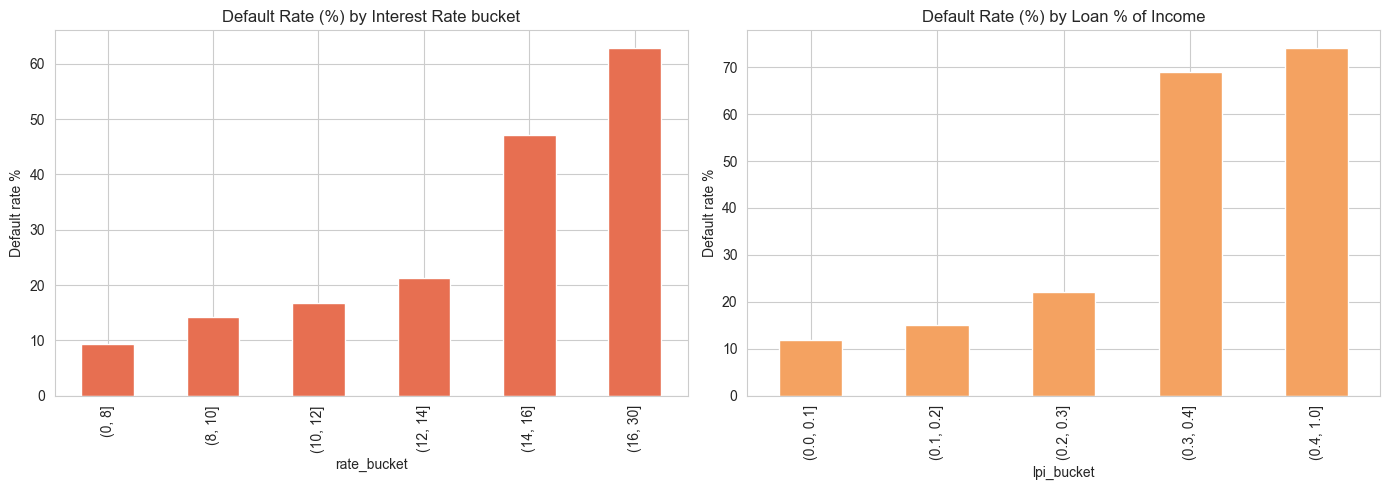

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["rate_bucket"] = pd.cut(df["loan_int_rate"], bins=[0, 8, 10, 12, 14, 16, 30])
(df.groupby("rate_bucket")["loan_status"].mean() * 100).plot(kind="bar", ax=axes[0], color="#e76f51")
axes[0].set_title("Default Rate (%) by Interest Rate bucket")
axes[0].set_ylabel("Default rate %")

df["lpi_bucket"] = pd.cut(df["loan_percent_income"], bins=[0, 0.1, 0.2, 0.3, 0.4, 1.0])
(df.groupby("lpi_bucket")["loan_status"].mean() * 100).plot(kind="bar", ax=axes[1], color="#f4a261")
axes[1].set_title("Default Rate (%) by Loan % of Income")
axes[1].set_ylabel("Default rate %")

plt.tight_layout()
plt.show()
df = df.drop(columns=["rate_bucket", "lpi_bucket"])

## Step 9: Correlation Heatmap
Numbers ke beech relation (-1 se +1). Target `loan_status` ke saath jis feature ka correlation zyada hai wo important hota hai. Do features aapas mein bahut zyada correlated hon (jaise age aur credit history length) to unme redundancy hoti hai.

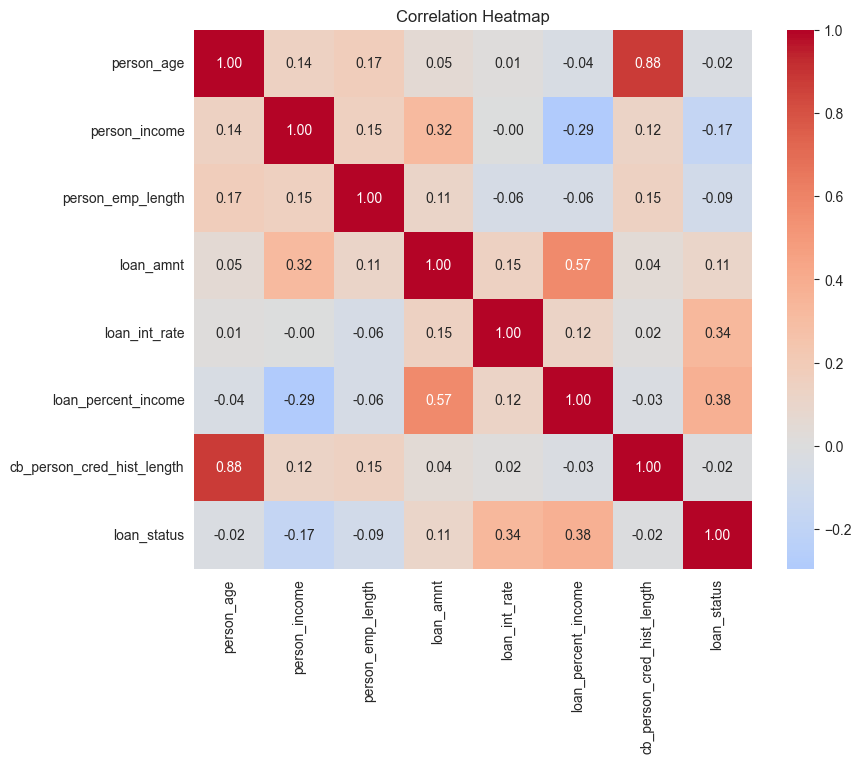

loan_percent_income           0.380
loan_int_rate                 0.336
loan_amnt                     0.106
cb_person_cred_hist_length   -0.016
person_age                   -0.022
person_emp_length            -0.086
person_income                -0.169
Name: loan_status, dtype: float64


In [16]:
corr = df[num_cols + ["loan_status"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

print(corr["loan_status"].drop("loan_status").sort_values(ascending=False).round(3))

### EDA ke insights — ye khud likho (interview ke liye)
Upar ke graphs dekh ke apne words mein 4-5 points likh lo. Example format (apne real graphs se match karke likhna):
- Default rate loan grade A se G ki taraf badhta hai.
- Jin customers ne pehle default kiya hai unka default rate zyada hai.
- Interest rate aur loan_percent_income badhne par default rate badhta hai.
- RENT par rehne wale customers ka default rate OWN walon se zyada hai.

## Step 10: Feature Engineering
Naye useful features banate hain. `cred_hist_to_age` = credit history length ÷ age → batata hai ki customer ne apni zindagi ka kitna hissa credit use kiya.

In [17]:
df["cred_hist_to_age"] = df["cb_person_cred_hist_length"] / df["person_age"]
df[["person_age", "cb_person_cred_hist_length", "cred_hist_to_age"]].head()

,person_age,cb_person_cred_hist_length,cred_hist_to_age
0,21,2,0.095238
1,25,3,0.120000
2,23,2,0.086957
3,24,4,0.166667
4,21,2,0.095238


## Step 11: Train / Test split
80% data train ke liye, 20% test ke liye. `stratify=y` se dono mein default ka ratio same rehta hai. `random_state=42` se har baar same split milta hai.

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="loan_status")
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train default %:", round(y_train.mean() * 100, 2), "| Test default %:", round(y_test.mean() * 100, 2))

Train: (25927, 12) | Test: (6482, 12)
Train default %: 21.87 | Test default %: 21.88


## Step 12: Preprocessing Pipeline
- **Numerical columns:** missing values median se fill + StandardScaler
- **Categorical columns:** missing values most-frequent se fill + OneHotEncoder (text ko 0/1 columns mein badalta hai)

Sab kuch Pipeline mein hai, isliye train ka hi data seekh kar test pe apply hota hai (**no data leakage**).

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])
print("Numeric features    :", num_features)
print("Categorical features:", cat_features)

Numeric features    : ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'cred_hist_to_age']
Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## Step 13: Models banao (Baseline vs Random Forest)
- **Logistic Regression** = simple baseline model
- **Random Forest** = zyada powerful model

`class_weight="balanced"` se imbalance handle hota hai — model minority class (default) ko zyada importance deta hai.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                     random_state=42, n_jobs=-1)),
])

## Step 14: 5-Fold Cross-Validation
Train data ko 5 hisson mein baant ke 5 baar train/validate karte hain. Isse pata chalta hai ki model ki performance stable hai ya sirf ek lucky split pe achhi aayi.

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = {}
for name, model in [("Logistic Regression", log_reg), ("Random Forest", rf)]:
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

cv_df = pd.DataFrame(cv_results).T.round(4)
cv_df.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cv_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8124,0.5506,0.7751,0.6439,0.8703
Random Forest,0.9309,0.9711,0.7049,0.8168,0.9291


## Step 15: Final models train karo aur test data pe evaluate karo

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)

def evaluate(name, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, proba)}

results = pd.DataFrame([evaluate("Logistic Regression", log_reg, X_test, y_test),
                        evaluate("Random Forest", rf, X_test, y_test)]).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8053,0.5379,0.7800,0.6367,0.8717
Random Forest,0.9349,0.9779,0.7186,0.8285,0.9366


### Metrics ka matlab (interview mein poochhenge)
- **Accuracy:** kitne predictions sahi the (imbalanced data mein misleading ho sakta hai)
- **Precision:** jitne ko "default" bola, un mein se kitne sach mein default the
- **Recall:** jitne sach mein default the, un mein se kitne pakde
- **F1:** precision aur recall ka balance
- **ROC-AUC:** model default aur non-default ko kitna achhe se alag kar pata hai (1 = perfect, 0.5 = random guess)

## Step 16: Confusion Matrix
Dikhata hai: kitne sahi pakde (True Positive/Negative), kitne galat (False Positive = achhe customer ko default bola, False Negative = default wale ko miss kar diya).

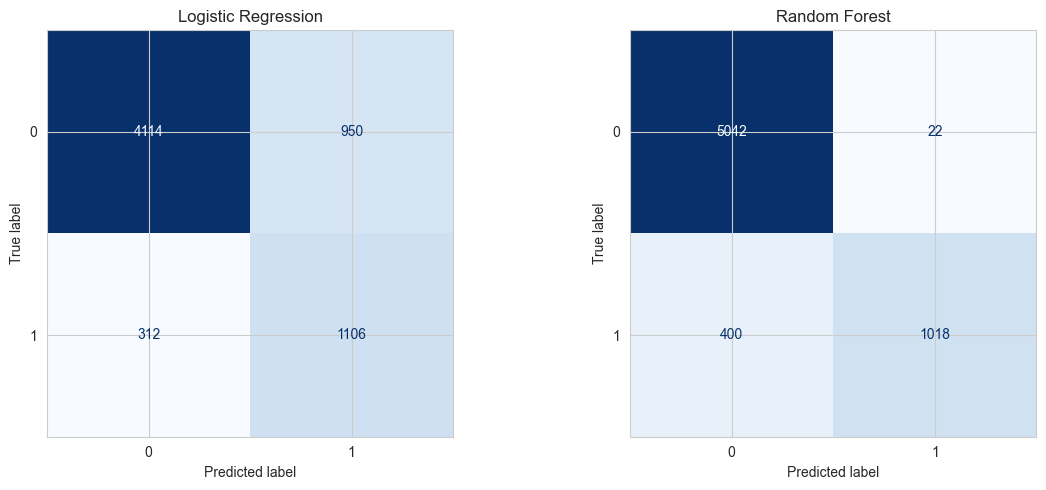

=== Random Forest: Classification Report ===
              precision    recall  f1-score   support

  No Default       0.93      1.00      0.96      5064
     Default       0.98      0.72      0.83      1418

    accuracy                           0.93      6482
   macro avg       0.95      0.86      0.89      6482
weighted avg       0.94      0.93      0.93      6482



In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, [("Logistic Regression", log_reg), ("Random Forest", rf)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("=== Random Forest: Classification Report ===")
print(classification_report(y_test, rf.predict(X_test), target_names=["No Default", "Default"]))

## Step 17: ROC Curve
Curve jitni upar-left corner ke paas hogi, model utna achha. Diagonal line = random guessing.

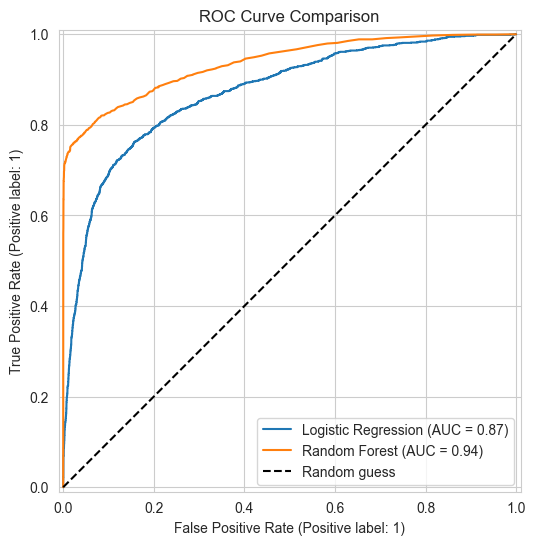

In [24]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=ax, name="Logistic Regression")
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=ax, name="Random Forest")
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

## Step 18: Hyperparameter Tuning (Random Forest)
`RandomizedSearchCV` alag-alag settings try karke best combination dhundta hai. (Thoda time lag sakta hai — 2 se 5 minute.)

In [25]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
}

search = RandomizedSearchCV(rf, param_dist, n_iter=10, cv=3, scoring="roc_auc",
                            random_state=42, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

print("Best params :", search.best_params_)
print("Best CV AUC :", round(search.best_score_, 4))
best_rf = search.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params : {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 20}
Best CV AUC : 0.928


In [26]:
tuned = evaluate("Random Forest (Tuned)", best_rf, X_test, y_test)
final_results = pd.concat([results, pd.DataFrame([tuned]).set_index("Model").round(4)])
final_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8053,0.5379,0.7800,0.6367,0.8717
Random Forest,0.9349,0.9779,0.7186,0.8285,0.9366
Random Forest (Tuned),0.9327,0.9546,0.7271,0.8255,0.9360


## Step 19: Feature Importance — Default ke top drivers
Random Forest batata hai ki kaunsa feature prediction mein sabse zyada kaam aaya. Ye graph tumhare resume ke 'top default drivers' wale point ka proof hai.

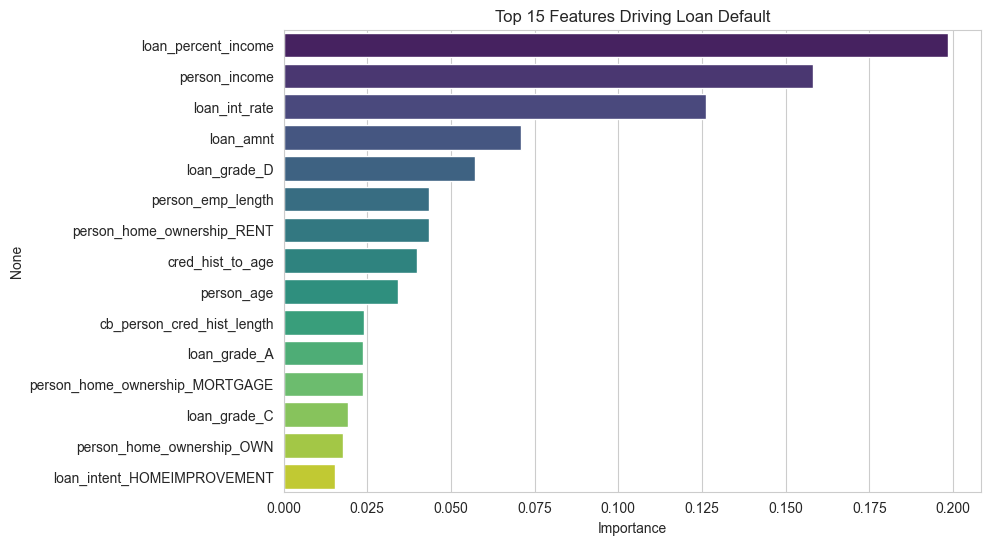

loan_percent_income    0.1985
person_income          0.1581
loan_int_rate          0.1261
loan_amnt              0.0708
loan_grade_D           0.0572
dtype: float64


In [27]:
feature_names = best_rf.named_steps["prep"].get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top15.values, y=top15.index, palette="viridis")
plt.title("Top 15 Features Driving Loan Default")
plt.xlabel("Importance")
plt.show()

print(top15.head(5).round(4))

## Step 20: Threshold Tuning (business thinking)
Default threshold 0.5 hota hai. Bank ko default miss karna zyada costly hai, isliye threshold kam karke **recall** badha sakte hain — lekin tab precision gir jaata hai. Ye trade-off dekho.

In [28]:
proba = best_rf.predict_proba(X_test)[:, 1]
rows_t = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    rows_t.append({"Threshold": t,
                   "Precision": precision_score(y_test, pred),
                   "Recall": recall_score(y_test, pred),
                   "F1": f1_score(y_test, pred)})
pd.DataFrame(rows_t).set_index("Threshold").round(3)

,Precision,Recall,F1
Threshold,,,
0.3,0.754,0.808,0.780
0.4,0.887,0.757,0.817
0.5,0.955,0.727,0.825
0.6,0.986,0.712,0.827
0.7,0.991,0.692,0.815


## Step 21: Model save karo
`joblib` se poora pipeline (preprocessing + model) ek file mein save hota hai. Streamlit app isi ko load karega.

In [29]:
import joblib
joblib.dump(best_rf, "model.pkl")
print("Model saved as model.pkl")

Model saved as model.pkl


## Step 22: Streamlit App
Niche wala cell **`app.py`** file bana dega. Phir terminal mein ye likho:
```
pip install streamlit
streamlit run app.py
```
Browser mein app khulega jahan user details bharke default probability dekh sakta hai.

In [30]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Loan Default Risk", page_icon="🏦")
model = joblib.load("model.pkl")

st.title("🏦 Loan Default Risk Scoring")
st.write("Customer ki details bharo aur default hone ki probability dekho.")

col1, col2 = st.columns(2)
with col1:
    age = st.number_input("Age", 18, 100, 30)
    income = st.number_input("Annual income", 1000, 5000000, 50000, step=1000)
    home = st.selectbox("Home ownership", ["RENT", "OWN", "MORTGAGE", "OTHER"])
    emp = st.number_input("Employment length (years)", 0.0, 60.0, 3.0)
    intent = st.selectbox("Loan intent", ["EDUCATION", "MEDICAL", "VENTURE",
                                          "PERSONAL", "DEBTCONSOLIDATION", "HOMEIMPROVEMENT"])
with col2:
    grade = st.selectbox("Loan grade", list("ABCDEFG"))
    amount = st.number_input("Loan amount", 500, 100000, 10000, step=500)
    rate = st.number_input("Interest rate (%)", 1.0, 30.0, 11.0)
    default_file = st.selectbox("Previous default on file", ["N", "Y"])
    hist = st.number_input("Credit history length (years)", 1, 40, 4)

if st.button("Check Risk"):
    row = pd.DataFrame([{
        "person_age": age, "person_income": income, "person_home_ownership": home,
        "person_emp_length": emp, "loan_intent": intent, "loan_grade": grade,
        "loan_amnt": amount, "loan_int_rate": rate,
        "loan_percent_income": amount / income,
        "cb_person_default_on_file": default_file,
        "cb_person_cred_hist_length": hist,
        "cred_hist_to_age": hist / age,
    }])
    prob = model.predict_proba(row)[0][1]
    st.metric("Default Probability", f"{prob:.1%}")
    if prob >= 0.5:
        st.error("High Risk — loan reject karne ki salah.")
    else:
        st.success("Low Risk — loan approve kiya ja sakta hai.")

Writing app.py


In [31]:
best = final_results.loc["Random Forest (Tuned)"]
base = final_results.loc["Logistic Regression"]

print("Total records used :", len(df))
print()
print(f"Random Forest (tuned) -> Accuracy: {best['Accuracy']:.1%} | ROC-AUC: {best['ROC-AUC']:.2f} | "
      f"Recall: {best['Recall']:.1%} | F1: {best['F1']:.2f}")
print(f"Logistic Regression   -> Accuracy: {base['Accuracy']:.1%} | ROC-AUC: {base['ROC-AUC']:.2f}")
print()
if best["ROC-AUC"] > base["ROC-AUC"]:
    print("Random Forest ne baseline ko outperform kiya -> resume mein 'outperforming Logistic Regression baseline' likh sakte ho.")
else:
    print("Random Forest baseline se behtar nahi hai -> resume se 'outperforming baseline' hata do.")
print()
print("Top 5 default drivers:")
print(top15.head(5).round(3).to_string())

Total records used : 32409

Random Forest (tuned) -> Accuracy: 93.3% | ROC-AUC: 0.94 | Recall: 72.7% | F1: 0.83
Logistic Regression   -> Accuracy: 80.5% | ROC-AUC: 0.87

Random Forest ne baseline ko outperform kiya -> resume mein 'outperforming Logistic Regression baseline' likh sakte ho.

Top 5 default drivers:
loan_percent_income    0.198
person_income          0.158
loan_int_rate          0.126
loan_amnt              0.071
loan_grade_D           0.057
